<a href="https://colab.research.google.com/github/jovinsoh16/Emotion-Classification-from-Public-Opinion/blob/main/Emotion_Classification_from_Public_Opinion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Instalasi Library yang Dibutuhkan

In [1]:
!pip install -q transformers[torch] datasets accelerate scikit-learn matplotlib seaborn

### Download & Upload Dataset
Gunakan cara ini apabila link github nya bermasalah.
1. Download seluruh file dataset (`.csv`) melalui https://drive.google.com/drive/folders/1bYFxATP5yqDD_RqChXdzTuFI97JZIhMF?usp=share_link
2. Buka panel **Files** di sebelah kiri Google Colab.
3. Drag & drop file-file CSV tersebut langsung ke area direktori utama (`/content/`).

#Load Dataset dan Analisis Distribusi Emosi

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
# Menggabungkan semua file CSV
base_url = "https://raw.githubusercontent.com/jovinsoh16/Emotion-Classification-from-Public-Opinion/main/data"
csv_files = ['AngerData.csv', 'FearData.csv', 'JoyData.csv', 'LoveData.csv', 'NeutralData.csv', 'SadData.csv']
df_list = []

for file in csv_files:
    file_url = f"{base_url}/{file}"
    # Membaca data dengan separator tab
    data = pd.read_csv(file_url, sep='\t')
    df_list.append(data)

# Gabungkan menjadi satu DataFrame utama
df = pd.concat(df_list, ignore_index=True)
df.dropna(subset=['Tweet', 'Label'], inplace=True)

In [4]:
# Mapping label string ke angka
label_map = {'Anger': 0, 'Fear': 1, 'Joy': 2, 'Love': 3, 'Neutral': 4, 'Sad': 5}
df['label'] = df['Label'].map(label_map)

print(f"Total dataset: {len(df)} baris.") # Menghitung total baris tweet pada semua file CSV
print(df['Label'].value_counts()) # Dihitung total baris tweet berdasarkan label

Total dataset: 7080 baris.
Label
Neutral    2001
Joy        1275
Anger      1130
Sad        1003
Fear        911
Love        760
Name: count, dtype: int64


/tmp/ipykernel_632/2591448105.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df, palette='viridis') # Frekuensi


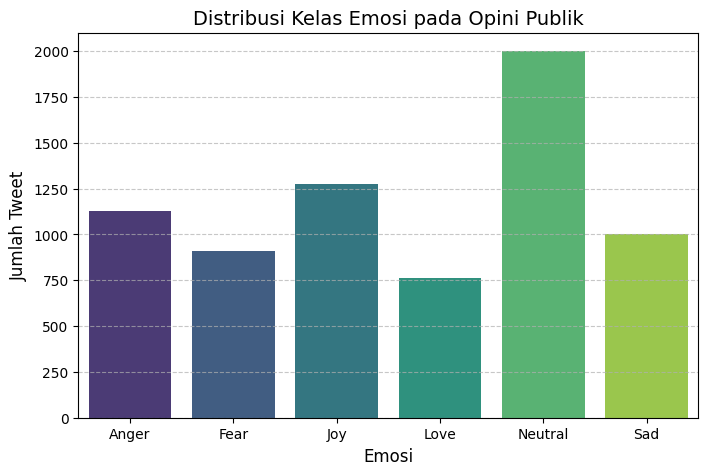

In [6]:
# Visualisasi distribusi emosi
plt.figure(figsize=(8, 5))
sns.countplot(x='Label', data=df, palette='viridis') # Frekuensi
plt.title('Distribusi Kelas Emosi pada Opini Publik', fontsize=14)
plt.xlabel('Emosi', fontsize=12)
plt.ylabel('Jumlah Tweet', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('distribusi_emosi.png', dpi=300)
plt.show()

In [9]:
# Split data menjadi train dan validation
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
# 80% data untuk training, 20% sisanya untuk validation (tes nyata)

#Tokenisasi menggunakan IndoBERT

In [7]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer

In [10]:
# Menggunakan pre-trained IndoBERT model dari IndoBenchmark bersumber dari HuggingFace
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Konversi pandas DataFrame ke HuggingFace Dataset
train_dataset = Dataset.from_pandas(train_df[['Tweet', 'label']].reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df[['Tweet', 'label']].reset_index(drop=True))

def tokenize_function(examples):
    # Truncation dan padding otomatis ke max_length 128 (cocok untuk tweet/teks pendek)
    return tokenizer(examples['Tweet'], padding="max_length", truncation=True, max_length=128)
    # Padding di teks < 128 token akan menambah "[PAD]" pada ruang kosong hingga tokennya genap 128

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/5664 [00:00<?, ? examples/s]

Map:   0%|          | 0/1416 [00:00<?, ? examples/s]

#Konfigurasi Model dan Parameter Fine-Tuning

In [11]:
import numpy as np
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import classification_report, accuracy_score
from transformers import EarlyStoppingCallback

In [12]:
# Inisialisasi Model IndoBERT untuk 6 kelas emosi
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=6)

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [13]:
# Fungsi metrics evaluasi model saat training berlangsung
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    acc = accuracy_score(labels, preds)

    return {"accuracy": acc}

In [14]:
# Pengaturan parameter training
training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=50,
    report_to="none"
)

In [15]:
# Definisikan objek Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)] # Ini mencegah overfitting
)

#Proses Training Fine-Tuning

In [16]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.709630,0.648244,0.778249
2,0.466489,0.685015,0.766243


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=708, training_loss=0.6673673357667222, metrics={'train_runtime': 321.7801, 'train_samples_per_second': 35.204, 'train_steps_per_second': 2.2, 'total_flos': 745157269684224.0, 'train_loss': 0.6673673357667222, 'epoch': 2.0})

#Evaluasi Model

In [17]:
from sklearn.metrics import confusion_matrix

In [18]:
# Prediksi data validasi
predictions_output = trainer.predict(tokenized_val)
preds = np.argmax(predictions_output.predictions, axis=-1)
labels = predictions_output.label_ids

In [19]:
# Print Classification Report Lengkap (Precision, Recall)
target_names = ['Anger', 'Fear', 'Joy', 'Love', 'Neutral', 'Sad']
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(labels, preds, target_names=target_names))


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       Anger       0.77      0.81      0.79       226
        Fear       0.81      0.87      0.84       182
         Joy       0.75      0.80      0.78       255
        Love       0.69      0.93      0.79       152
     Neutral       0.82      0.65      0.72       400
         Sad       0.82      0.77      0.80       201

    accuracy                           0.78      1416
   macro avg       0.78      0.81      0.79      1416
weighted avg       0.78      0.78      0.78      1416



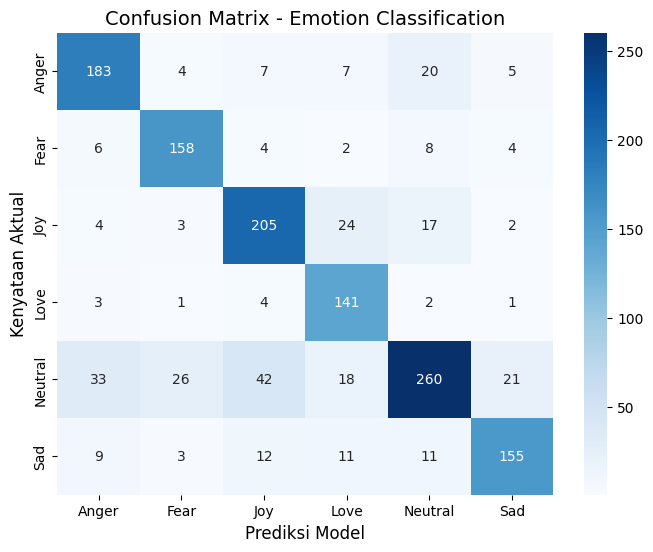

In [21]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(labels, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Emotion Classification', fontsize=14)
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Kenyataan Aktual', fontsize=12)
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

#Eksekusi

In [22]:
def prediksi_emosi_publik(teks):
    # Map inverse dari angka ke string emosi
    inverse_label_map = {0: 'Anger 😡', 1: 'Fear 😨', 2: 'Joy 😂', 3: 'Love 😍', 4: 'Neutral 😐', 5: 'Sad 😭'}

    # Tokenisasi input teks baru
    inputs = tokenizer(teks, return_tensors="pt", padding=True, truncation=True, max_length=128)

    # Pindahkan tensor ke GPU jika tersedia
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    model.to(device)

    # Prediksi tanpa kalkulasi gradien (cepat)
    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    pred_class = torch.argmax(logits, dim=-1).item()

    return inverse_label_map[pred_class]

# Untuk demo nanti
print("=== ANALISIS EMOSI w/IndoBERT ===")
print("Silakan masukkan kalimat opini publik secara bebas.")
print("Ketik 'keluar' jika ingin menghentikan program demo.\n")

while True:
    # Mengambil input teks secara langsung dari user di Colab
    opini_user = input("Masukkan kalimat opini / tweet: ")

    # Cek jika user ingin menyudahi demo
    if opini_user.lower() == 'keluar':
        print("\nProgram berhenti. Terima kasih!")
        break

    # Validasi jika user tidak mengetik apa-apa langsung enter
    if opini_user.strip() == "":
        print("⚠️ Teks tidak boleh kosong. Silakan masukkan kalimat.\n")
        continue

    # Jalankan prediksi model
    hasil_emosi = prediksi_emosi_publik(opini_user)

    # Tampilkan hasil secara rapi
    print(f"Hasil Klasifikasi Emosi -> {hasil_emosi}")
    print("-" * 60 + "\n")

=== ANALISIS EMOSI w/IndoBERT ===
Silakan masukkan kalimat opini publik secara bebas.
Ketik 'keluar' jika ingin menghentikan program demo.

Masukkan kalimat opini / tweet: "anjir sumpah kesel banget gue, udah nunggu 2 jam ojolnya malah dicancel sepihak
Hasil Klasifikasi Emosi -> Anger 😡
------------------------------------------------------------

Masukkan kalimat opini / tweet: wah makasih banget ya udah ngilangin file tugas gue, hebat lo emang
Hasil Klasifikasi Emosi -> Joy 😂
------------------------------------------------------------

Masukkan kalimat opini / tweet: mantap, wifi kos mati lagi pas deadline. pelayanan terbaik
Hasil Klasifikasi Emosi -> Joy 😂
------------------------------------------------------------

Masukkan kalimat opini / tweet: tanggung jawab lo mana? udah gue tunggu dari kemarin
Hasil Klasifikasi Emosi -> Neutral 😐
------------------------------------------------------------

Masukkan kalimat opini / tweet: tadi ada suara aneh di atap, gue diem aja ga berani g